# 🏠 Bengaluru House Price Analysis
**Tools used:** Python, Pandas, NumPy, Matplotlib, Seaborn

## About this project
Buying a house in Bengaluru is costly, and the price changes a lot from one area to another. In this project I analyse about 11,000 house listings to find out **what actually decides the price of a house**.

**Note:** Price is in **lakhs** (1 lakh = 1,00,000 rupees).

## Questions I want to answer
1. Which areas are the most and least expensive?
2. Does a bigger house always mean a higher price?
3. Does the type of area (Plot, Super built-up, etc.) change the price?
4. Are ready-to-move houses costlier than under-construction ones?
5. How is the market divided between budget and luxury houses?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings("ignore")

os.makedirs("images", exist_ok=True)   # charts will be saved here

sns.set_theme(style="whitegrid")

`step 2 Loading the data `

In [2]:
df = pd.read_csv("Bengaluru_House_Data_Cleaned.csv")
df["area_type"] = df["area_type"].str.replace(r"\s+", " ", regex=True)   # fix double spaces in names
print("Rows, Columns:", df.shape)
df.head()

Rows, Columns: (11055, 14)


,area_type,availability,location,size,total_sqft,bath,balcony,price,bhk,is_ready,price_per_sqft,sqft_per_bhk,price_category,location_grouped
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,1056.0,2.0,1.0,39.07,2,Under Construction,3699.81,528.0,Budget (<50L),Electronic City Phase II
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,2600.0,5.0,3.0,120.00,4,Ready,4615.38,650.0,Premium (100-200L),Chikka Tirupathi
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,1440.0,2.0,3.0,62.00,3,Ready,4305.56,480.0,Mid (50-100L),Uttarahalli
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,1521.0,3.0,1.0,95.00,3,Ready,6245.89,507.0,Mid (50-100L),Lingadheeranahalli
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,1200.0,2.0,1.0,51.00,2,Ready,4250.00,600.0,Mid (50-100L),Kothanur


### Here the thing i had done to clean the raw data

1. `Society` column dropped because `41% missing value` 
2. Dupicate listing `removed(568rows)` 
3. Dropped rowsize filled with median (bath,balcony) since few missing values it had.
4. here the text like 2BHK or 4Bedroom took the number out into a new colum `BHK`
5. total_sqft had ranges(2100-2850) and units (34 sq.meter) took the avg of ranges,converts units to sqft
6. Availability had random dates make it simple `Ready or Under Construction`
7. Removed Some Outliers

## Step 3: Quick look at the data

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11055 entries, 0 to 11054
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   area_type         11055 non-null  str    
 1   availability      11055 non-null  str    
 2   location          11055 non-null  str    
 3   size              11055 non-null  str    
 4   total_sqft        11055 non-null  float64
 5   bath              11055 non-null  float64
 6   balcony           11055 non-null  float64
 7   price             11055 non-null  float64
 8   bhk               11055 non-null  int64  
 9   is_ready          11055 non-null  str    
 10  price_per_sqft    11055 non-null  float64
 11  sqft_per_bhk      11055 non-null  float64
 12  price_category    11055 non-null  str    
 13  location_grouped  11055 non-null  str    
dtypes: float64(6), int64(1), str(7)
memory usage: 1.2 MB


In [4]:
df.describe().round(1)

,total_sqft,bath,balcony,price,bhk,price_per_sqft,sqft_per_bhk
count,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0,11055.0
mean,1518.4,2.5,1.6,96.6,2.6,5875.5,583.1
std,857.6,1.0,0.8,101.6,0.9,2716.4,188.0
min,300.0,1.0,0.0,10.0,1.0,2320.0,300.0
25%,1105.0,2.0,1.0,48.7,2.0,4202.5,495.0
50%,1295.0,2.0,2.0,68.0,2.0,5213.9,561.2
75%,1662.0,3.0,2.0,105.0,3.0,6644.3,626.9
max,30400.0,16.0,3.0,2200.0,16.0,21875.0,6000.0


**What I understood:** There are no missing values left. The average price (~97 lakh) is much higher than the median (68 lakh), which already hints that a few very expensive houses are pulling the average up.

## Step 4: Analysis with Pandas
Before drawing charts, I get exact numbers using `groupby`, `value_counts` and `corr`.

### 4.1 Which areas are the most and least expensive? (price per sqft)
I only use areas with **at least 15 listings**, so the average is trustworthy.

In [5]:
loc_stats = df.groupby("location")["price_per_sqft"].agg(["mean", "count"])
loc_stats = loc_stats[loc_stats["count"] >= 15].round(0)

top10 = loc_stats.sort_values("mean", ascending=False).head(10)
bottom10 = loc_stats.sort_values("mean").head(10)

print("10 MOST EXPENSIVE AREAS")
display(top10)
print("10 CHEAPEST AREAS")
display(bottom10)

10 MOST EXPENSIVE AREAS


,mean,count
location,,
Rajaji Nagar,12997.0,94
Indira Nagar,11727.0,38
Malleshwaram,11477.0,45
Cooke Town,10819.0,16
Basaveshwara Nagar,9953.0,16
Frazer Town,9727.0,28
Koramangala,9497.0,63
Basavangudi,9346.0,26
Hebbal Kempapura,9092.0,30


10 CHEAPEST AREAS


,mean,count
location,,
Ananth Nagar,3017.0,25
Chandapura,3037.0,68
Bommasandra Industrial Area,3165.0,25
Attibele,3187.0,34
Kammasandra,3358.0,26
Hoskote,3471.0,16
Anekal,3638.0,28
Begur Road,3638.0,53
Electronic City Phase II,3694.0,120


### ✅ Conclusion 1 – Location
The costliest area is **Rajaji Nagar (about ₹12,997 per sqft)**, followed by Indira Nagar and Malleshwaram. The cheapest areas are **Ananth Nagar and Chandapura (about ₹3,000 per sqft)**.
So the same 1 sqft costs around **4 times more** in the central areas than in the outer areas.

*Simple meaning: the area you choose matters a lot. Central areas are expensive, areas far from the city centre are much cheaper.*

### 4.2 Does the type of area change the price?

In [6]:
df.groupby("area_type").agg(
    median_price=("price", "median"),
    average_price=("price", "mean"),
    listings=("price", "count")
).round(1)

,median_price,average_price,listings
area_type,,,
Built-up Area,68.0,94.3,2167
Carpet Area,69.5,89.1,80
Plot Area,130.0,182.5,916
Super built-up Area,65.0,87.4,7892


### ✅ Conclusion 2 – Area type
**Plot Area** houses are the most expensive, with a median of **130 lakh**. The other three types (Super built-up, Built-up, Carpet) are close to each other at **65 to 70 lakh**.
Most listings (about 7,900) are Super built-up.

*Simple meaning: plots cost almost double because you also pay for the land, which is the costliest part in Bengaluru.*

### 4.3 How does price change with BHK?

In [7]:
df.groupby("bhk")["price"].agg(["median", "count"]).head(7)

,median,count
bhk,,
1,34.225,574
2,54.000,5026
3,88.000,4304
4,200.000,873
5,211.500,138
6,175.000,70
7,150.000,31


### ✅ Conclusion 3 – BHK
The median price keeps rising with BHK: **1 BHK ≈ 34 lakh, 2 BHK ≈ 54 lakh, 3 BHK ≈ 88 lakh, 4 BHK ≈ 200 lakh**.
Also, **2 and 3 BHK houses make up about 84%** of all listings, so they are the most popular choice.

*Simple meaning: most people buy 2 or 3 BHK. Going from 3 BHK to 4 BHK more than doubles the price.*

### 4.4 Ready to move vs Under construction

In [8]:
df.groupby("is_ready").agg(
    median_price=("price", "median"),
    median_price_per_sqft=("price_per_sqft", "median"),
    listings=("price", "count")
).round(0)

,median_price,median_price_per_sqft,listings
is_ready,,,
Ready,69.0,5204.0,8656
Under Construction,65.0,5250.0,2399


### ✅ Conclusion 4 – Ready vs Under construction
Ready houses have a median of **69 lakh** and under-construction houses **65 lakh**. Per sqft the price is almost the same (about ₹5,200 vs ₹5,250).

*Simple meaning: waiting for a house to be built does not give a big discount. Whether a house is ready or not is not a major price factor.*

### 4.5 Budget vs luxury – how is the market divided?

In [9]:
(df["price_category"].value_counts(normalize=True) * 100).round(1)

price_category
Mid (50-100L)         45.6
Budget (<50L)         28.2
Premium (100-200L)    18.2
Luxury (>200L)         8.0
Name: proportion, dtype: float64

### ✅ Conclusion 5 – Market split
About **46% houses are Mid-range (50–100 lakh)**, 28% are Budget (under 50 lakh), 18% Premium and only **8% are Luxury (above 200 lakh)**.
The average price is ~97 lakh but the median is only 68 lakh.

*Simple meaning: the market is mostly middle-class priced. Few luxury houses are very costly and they push the average up, so the **median** is a better measure of a "normal" price.*

### 4.6 Correlation
Correlation tells how strongly two columns move together. It goes from **-1 to +1**. Closer to +1 means "when one goes up, the other also goes up".

In [10]:
cols = ["price", "total_sqft", "bhk", "bath", "balcony"]
corr = df[cols].corr().round(2)
corr

,price,total_sqft,bhk,bath,balcony
price,1.00,0.80,0.51,0.54,0.14
total_sqft,0.80,1.00,0.67,0.68,0.22
bhk,0.51,0.67,1.00,0.87,0.25
bath,0.54,0.68,0.87,1.00,0.25
balcony,0.14,0.22,0.25,0.25,1.00


### ✅ Conclusion 6 – What affects price?
Price has a correlation of **0.80 with total_sqft**, 0.54 with bathrooms, 0.51 with BHK and only **0.14 with balcony**.

*Simple meaning: the size of the house (sqft) is the strongest number-based factor. The number of balconies hardly matters.*

## Step 5: Visualisation
Each chart has a short reason (why I made it) and a conclusion (what it tells us).

### Chart 1: Distribution of house prices (histogram)
**Why:** To see how prices are spread and where most houses lie.

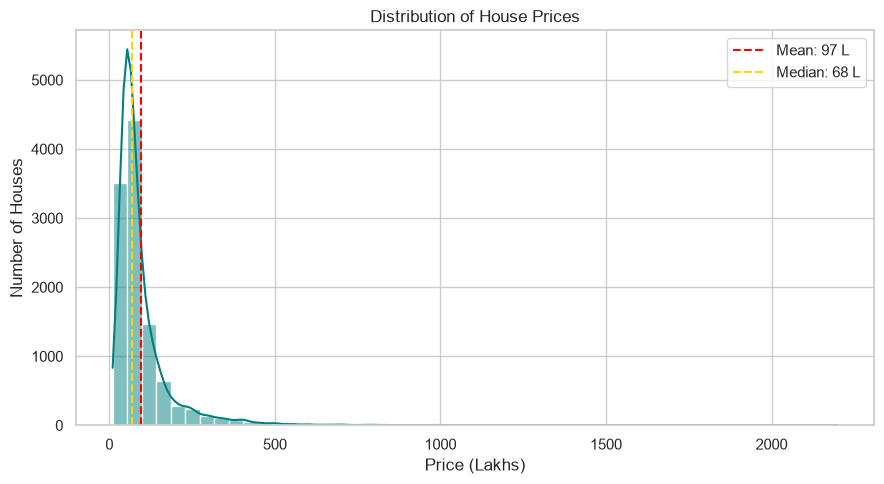

In [11]:
plt.figure(figsize=(9, 5))
sns.histplot(df["price"], bins=50, kde=True, color="teal")
plt.axvline(df["price"].mean(), color="red", linestyle="--", label=f"Mean: {df['price'].mean():.0f} L")
plt.axvline(df["price"].median(), color="gold", linestyle="--", label=f"Median: {df['price'].median():.0f} L")
plt.title("Distribution of House Prices")
plt.xlabel("Price (Lakhs)")
plt.ylabel("Number of Houses")
plt.legend()
plt.tight_layout()
plt.savefig("images/01_price_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusion:** Most houses are priced below 100 lakh. The graph has a long tail on the right side, which means a few very expensive houses exist. Because of them the **mean (red) is higher than the median (yellow)**.

### Chart 2: Number of houses by BHK (countplot)
**Why:** To know which house size is the most common.

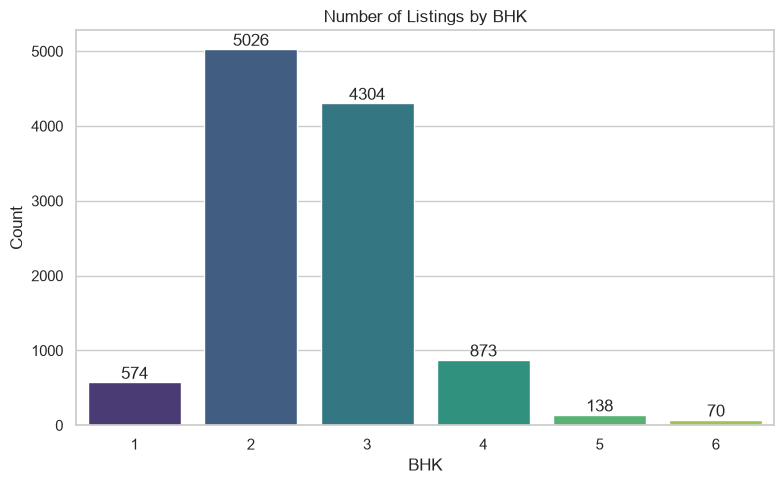

In [12]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(x="bhk", data=df[df["bhk"] <= 6], palette="viridis")
for c in ax.containers:
    ax.bar_label(c)
plt.title("Number of Listings by BHK")
plt.xlabel("BHK")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig("images/02_bhk_count.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusion:** 2 BHK (5,026) and 3 BHK (4,304) are by far the most common. 1 BHK and 4 BHK are less common and 5+ BHK is very rare. The market is built mainly for families who want 2 or 3 bedrooms.

### Chart 3: Price by area type (boxplot)
**Why:** To compare the price range of each area type.
*How to read a boxplot: the line inside the box is the median, the box holds the middle 50% of houses, and dots far away are very expensive houses.*

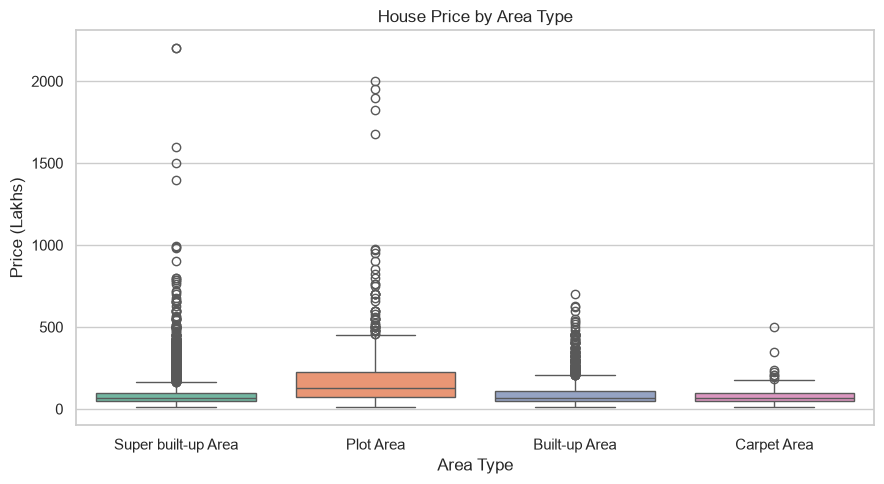

In [13]:
plt.figure(figsize=(9, 5))
sns.boxplot(x="area_type", y="price", data=df, palette="Set2")
plt.title("House Price by Area Type")
plt.xlabel("Area Type")
plt.ylabel("Price (Lakhs)")
plt.tight_layout()
plt.savefig("images/03_price_by_area_type.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusion:** The Plot Area box sits much higher than the others and is also wider, so plots are costlier and their prices vary more. Super built-up, Built-up and Carpet area are at a similar level.

### Chart 4: 10 most expensive areas (Seaborn bar chart)
**Why:** To answer our first question visually.

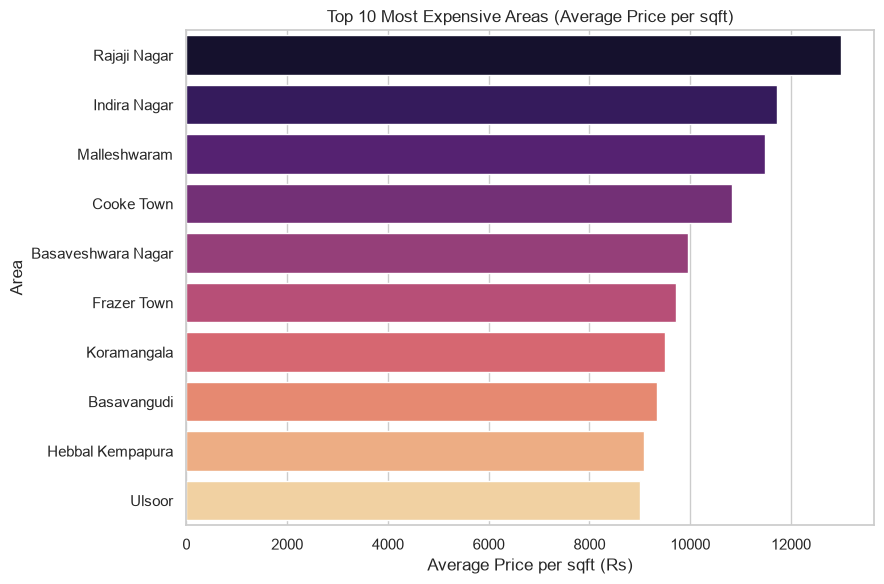

In [14]:
plt.figure(figsize=(9, 6))
sns.barplot(x=top10["mean"], y=top10.index, palette="magma")
plt.title("Top 10 Most Expensive Areas (Average Price per sqft)")
plt.xlabel("Average Price per sqft (Rs)")
plt.ylabel("Area")
plt.tight_layout()
plt.savefig("images/04_top10_expensive.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusion:** Rajaji Nagar is at the top, then Indira Nagar and Malleshwaram. These are well-developed, central areas of Bengaluru, which is why their rates are so high.

### Chart 5: 10 cheapest areas (Matplotlib bar chart)
**Why:** To help buyers with a small budget. This one is made with pure Matplotlib.

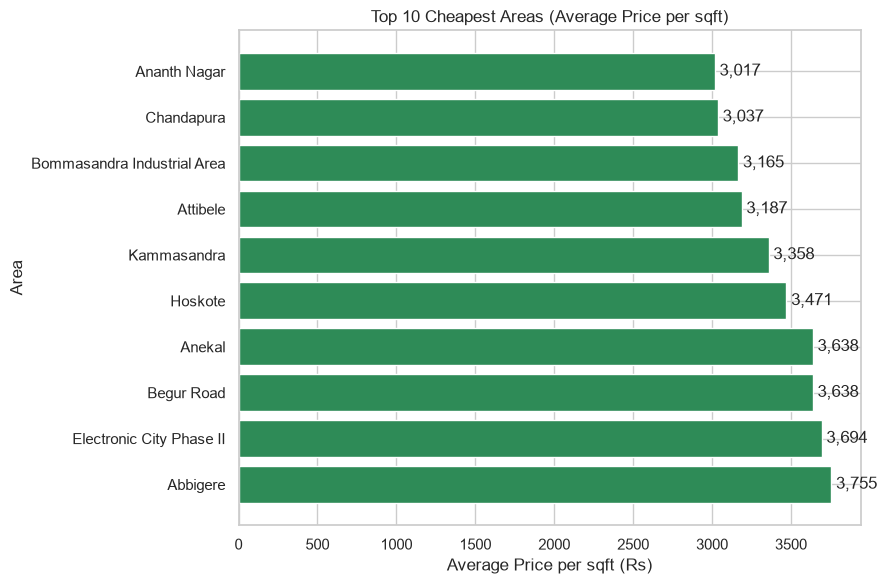

In [15]:
plt.figure(figsize=(9, 6))
plt.barh(bottom10.index, bottom10["mean"], color="seagreen")
plt.gca().invert_yaxis()
for i, v in enumerate(bottom10["mean"]):
    plt.text(v + 30, i, f"{v:,.0f}", va="center")
plt.title("Top 10 Cheapest Areas (Average Price per sqft)")
plt.xlabel("Average Price per sqft (Rs)")
plt.ylabel("Area")
plt.tight_layout()
plt.savefig("images/05_top10_cheapest.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusion:** Areas like Ananth Nagar, Chandapura, Bommasandra and Attibele cost only about ₹3,000–3,200 per sqft. Most of them are on the outskirts or near industrial zones, so a buyer with a limited budget should look there.

### Chart 6: Size vs price (scatter plot with trend line)
**Why:** To check whether bigger houses really cost more.

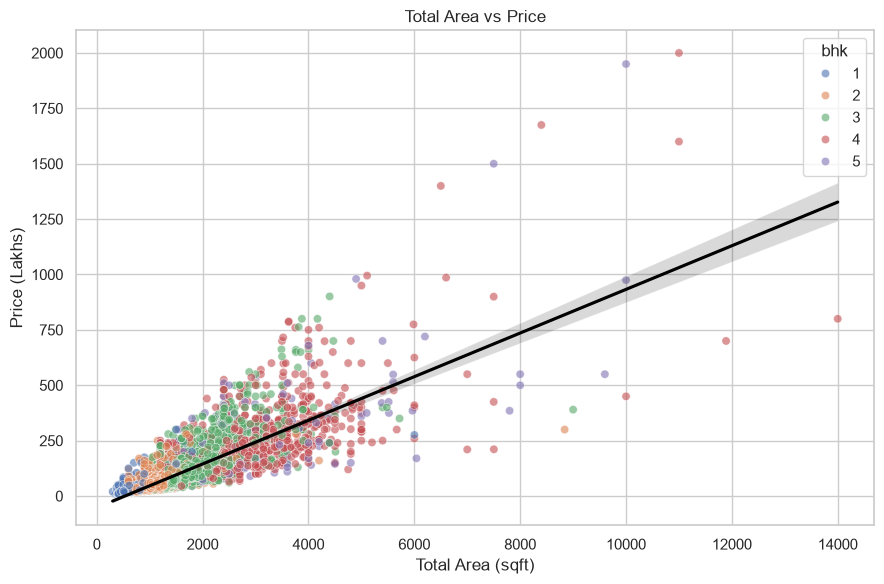

In [16]:
plt.figure(figsize=(9, 6))
subset = df[df["bhk"] <= 5]
sns.scatterplot(x="total_sqft", y="price", hue="bhk", data=subset, palette="deep", alpha=0.6)
sns.regplot(x="total_sqft", y="price", data=subset, scatter=False, color="black")
plt.title("Total Area vs Price")
plt.xlabel("Total Area (sqft)")
plt.ylabel("Price (Lakhs)")
plt.tight_layout()
plt.savefig("images/06_sqft_vs_price.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusion:** The dots go upward from left to right, so **bigger houses cost more**. This matches the 0.80 correlation we saw earlier. The dots spread out for large sizes because location also changes the price – two houses of the same size can have very different prices.

### Chart 7: Correlation heatmap
**Why:** To see all relationships in one picture. Dark red = strong positive relation, blue = weak or negative.

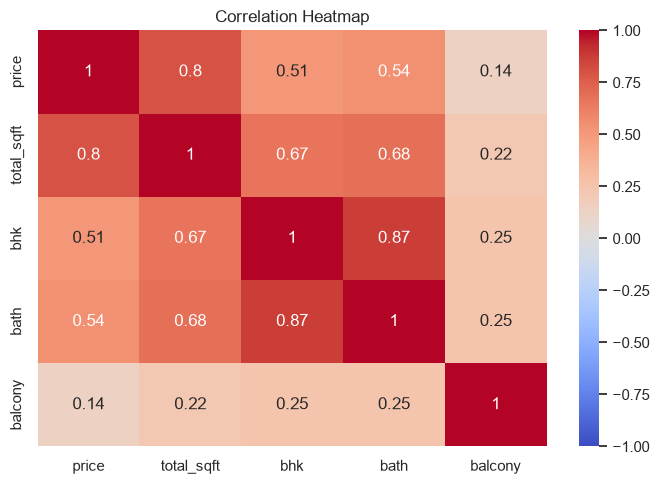

In [17]:
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("images/07_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusion:** Price is most related to total_sqft (0.80). BHK and bathrooms are strongly related to each other (0.87), which makes sense because a house with more bedrooms usually has more bathrooms. Balcony has almost no effect on price.

### Chart 8: Ready vs Under construction (boxplot)
**Why:** To check if the status of the house changes the price.

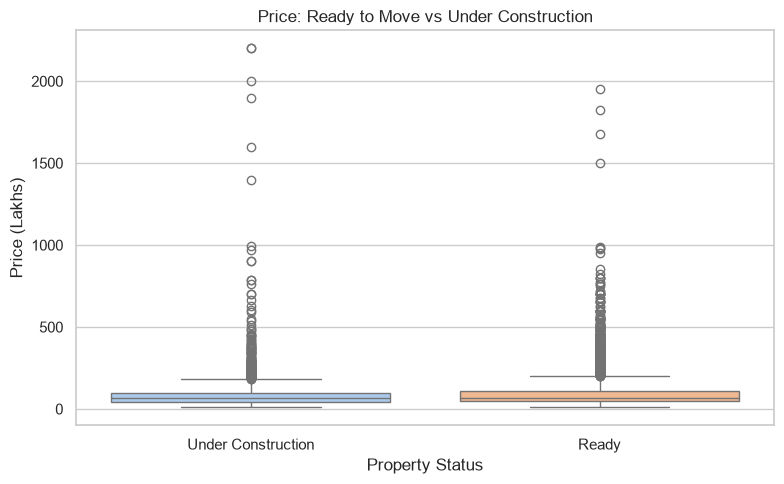

In [18]:
plt.figure(figsize=(8, 5))
sns.boxplot(x="is_ready", y="price", data=df, palette="pastel")
plt.title("Price: Ready to Move vs Under Construction")
plt.xlabel("Property Status")
plt.ylabel("Price (Lakhs)")
plt.tight_layout()
plt.savefig("images/08_ready_vs_construction.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusion:** Both boxes are almost at the same level. So house status has only a small effect on the price. Ready houses are only a little costlier.

### Chart 9: Budget category share (pie chart)
**Why:** To see in one picture how the market is divided.

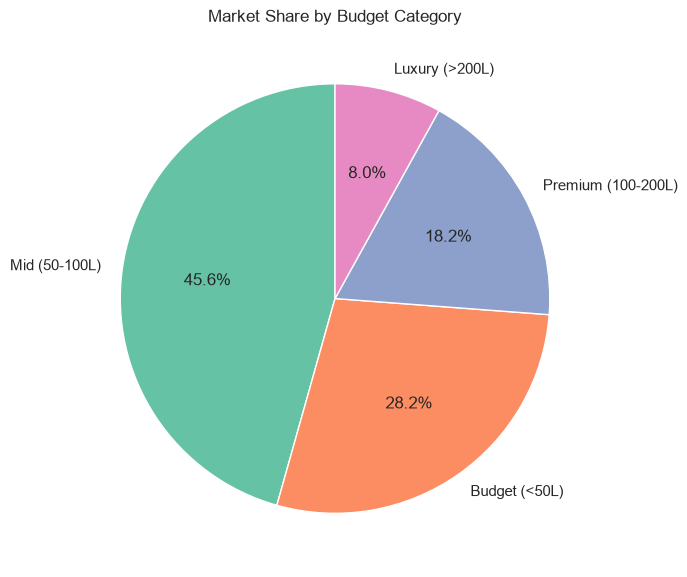

In [19]:
share = df["price_category"].value_counts()
plt.figure(figsize=(7, 7))
plt.pie(share, labels=share.index, autopct="%1.1f%%", startangle=90,
        colors=sns.color_palette("Set2"))
plt.title("Market Share by Budget Category")
plt.tight_layout()
plt.savefig("images/09_budget_share.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusion:** Mid-range houses (50–100 lakh) take the biggest share at 46%. Luxury houses above 200 lakh are only 8%. A normal buyer mostly finds options in the mid-range and budget segment.

## Step 6: Final Conclusion

1. **Location is the biggest factor.** Rajaji Nagar costs about ₹13,000 per sqft while Ananth Nagar costs about ₹3,000, around 4 times less.
2. **Size matters most among the numbers.** Correlation of price with total sqft is 0.80, much higher than bathrooms (0.54), BHK (0.51) or balcony (0.14).
3. **2 and 3 BHK dominate** the market with about 84% of listings.
4. **Plots are the costliest** (median 130 lakh) compared to about 65–70 lakh for other area types.
5. **Ready vs under construction makes little difference** (69 vs 65 lakh median).
6. **The market is mostly mid-range.** 46% Mid, 28% Budget, 18% Premium, 8% Luxury. A few luxury houses pull the average (97 lakh) above the median (68 lakh).

### Limitations
- The data has no date column, so I cannot study price changes over time.
- Some location names may be spelled differently for the same place.
- These are listing prices, not the final price at which houses were sold.

### Future work
- Build a machine learning model (like Linear Regression) to predict house price.
- Show the areas on a Bengaluru map.